In [1]:
pip install -U shap

You should consider upgrading via the '/Users/pranay/secom-yield-analysis/.secom/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, joblib, shap
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)

train = pd.read_csv("../data/processed/train.csv", parse_dates=["timestamp"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["timestamp"])
saved = joblib.load("../data/processed/xgb.joblib")
model, feats = saved["model"], saved["features"]

X_train, y_train = train[feats], train["fail"]

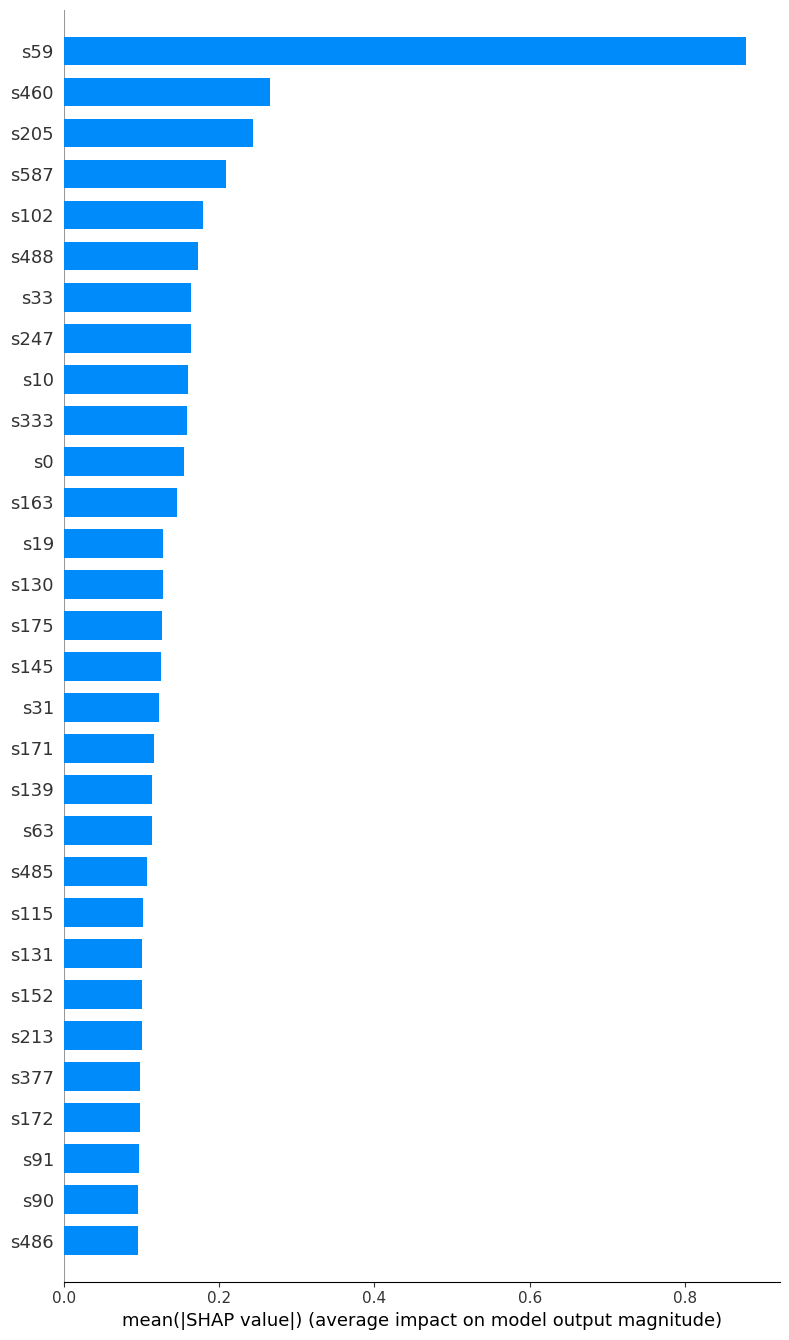

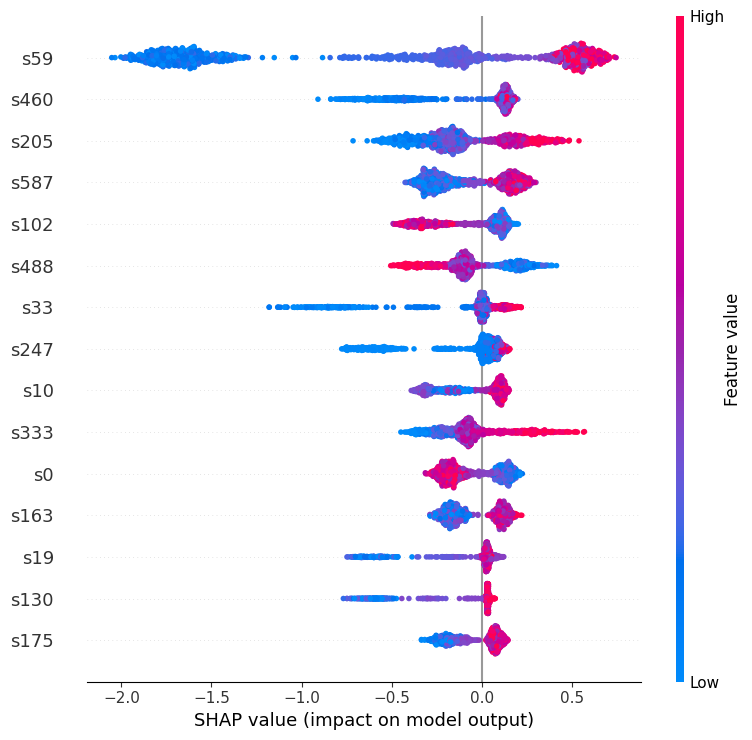

In [5]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_train)

shap.summary_plot(sv, X_train, plot_type="bar", max_display=30, show=False)
plt.tight_layout(); plt.savefig("../figures/shap_bar.png", dpi=150); plt.show()

shap.summary_plot(sv, X_train, max_display=15, show=False)
plt.tight_layout(); plt.savefig("../figures/shap_beeswarm.png", dpi=150); plt.show()

In [6]:
 importance = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
top10 = importance.head(10)
print(top10)
top10.to_csv("../data/processed/top_sensors.csv")

s59     0.878405
s460    0.265314
s205    0.243530
s587    0.209215
s102    0.179325
s488    0.173247
s33     0.164163
s247    0.163926
s10     0.160066
s333    0.158487
dtype: float32


/var/folders/zk/_z3grjyj45vcrqmydbtbqlsc0000gn/T/ipykernel_80838/3064237190.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X_train[s][y_train == 0], X_train[s][y_train == 1]],
/var/folders/zk/_z3grjyj45vcrqmydbtbqlsc0000gn/T/ipykernel_80838/3064237190.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X_train[s][y_train == 0], X_train[s][y_train == 1]],
/var/folders/zk/_z3grjyj45vcrqmydbtbqlsc0000gn/T/ipykernel_80838/3064237190.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X_train[s][y_train == 0], X_train[s][y_train == 1]],
/var/folders/zk/_z3grjyj45vcrqmydbtbqlsc0000gn

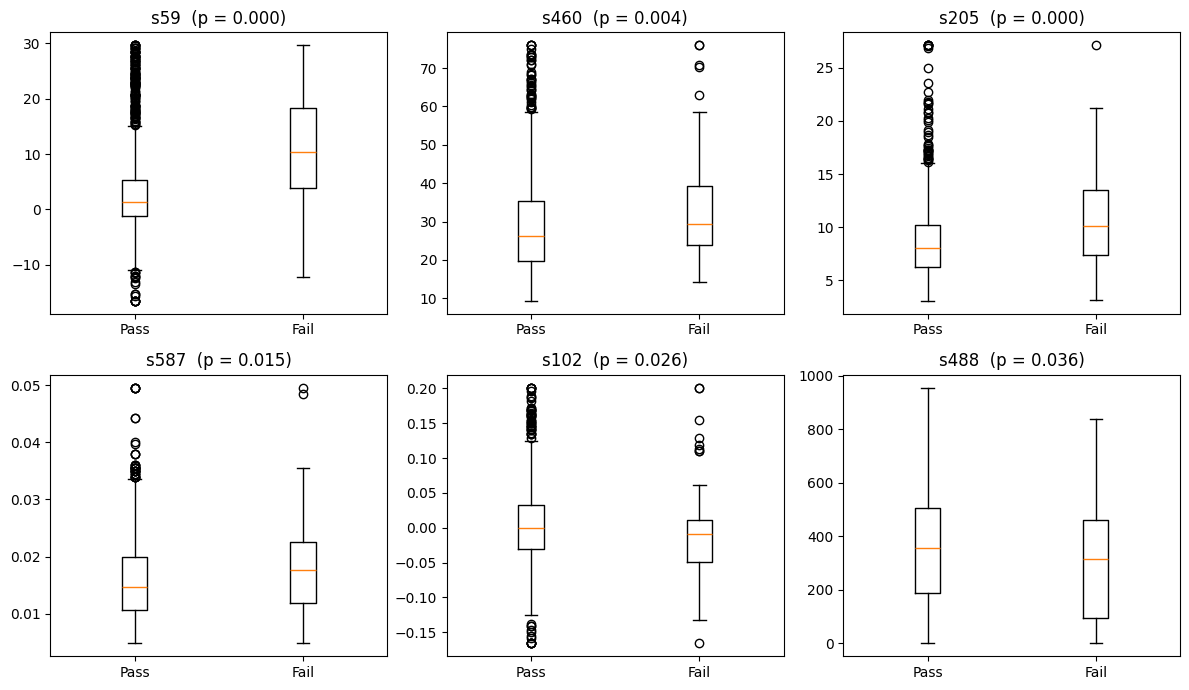

In [7]:
from scipy.stats import mannwhitneyu

top6 = top10.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, s in zip(axes.flat, top6):
    p = mannwhitneyu(X_train[s][y_train == 0], X_train[s][y_train == 1]).pvalue
    ax.boxplot([X_train[s][y_train == 0], X_train[s][y_train == 1]],
               labels=["Pass", "Fail"])
    ax.set_title(f"{s}  (p = {p:.3f})")
plt.tight_layout(); plt.savefig("../figures/top_sensors_pass_fail.png", dpi=150); plt.show()

In [9]:
from scipy.stats import mannwhitneyu

i59 = feats.index("s59")
print("s59 corr(value, SHAP):", np.corrcoef(X_train["s59"], sv[:, i59])[0, 1].round(2))

for s in top10.index[:6]:
    p = mannwhitneyu(X_train[s][y_train == 0], X_train[s][y_train == 1]).pvalue
    print(f"{s}: p = {p:.4f} | pass median {X_train[s][y_train==0].median():.3f} "
          f"| fail median {X_train[s][y_train==1].median():.3f}")

s59 corr(value, SHAP): 0.77
s59: p = 0.0000 | pass median 1.439 | fail median 10.437
s460: p = 0.0035 | pass median 26.163 | fail median 29.432
s205: p = 0.0000 | pass median 8.080 | fail median 10.110
s587: p = 0.0151 | pass median 0.015 | fail median 0.018
s102: p = 0.0260 | pass median 0.000 | fail median -0.008
s488: p = 0.0357 | pass median 356.938 | fail median 316.957


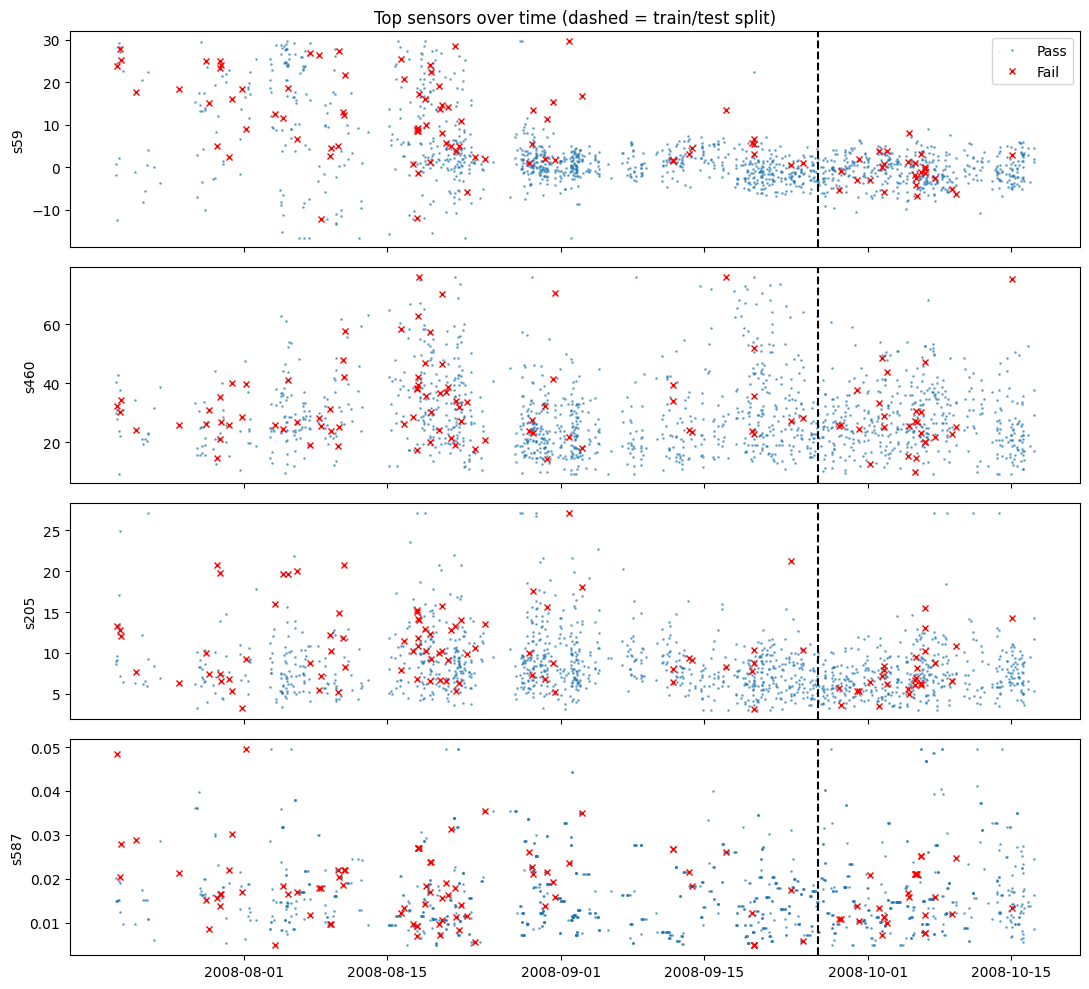

In [8]:
full = pd.concat([train, test]).sort_values("timestamp")
split_time = test["timestamp"].min()

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
for ax, s in zip(axes, top10.index[:4]):
    ax.plot(full["timestamp"], full[s], ".", ms=2, alpha=0.5, label="Pass")
    f = full[full["fail"] == 1]
    ax.plot(f["timestamp"], f[s], "rx", ms=5, label="Fail")
    ax.axvline(split_time, color="k", ls="--")
    ax.set_ylabel(s)
axes[0].legend(); axes[0].set_title("Top sensors over time (dashed = train/test split)")
plt.tight_layout(); plt.savefig("../figures/top_sensors_time.png", dpi=150); plt.show()